# [Lab Session 4](deconvolution.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

In [3]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

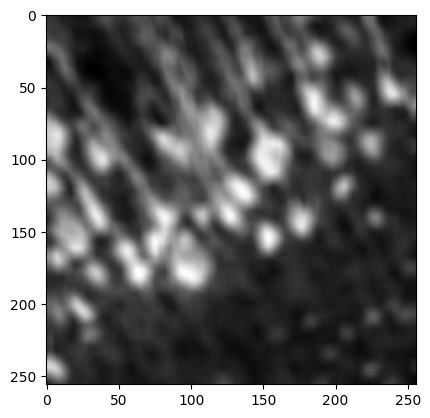

In [4]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

img_upsf = conv(img, psf, mode='same',
boundary='symm')

plt.imshow(img_upsf, 'grey')

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

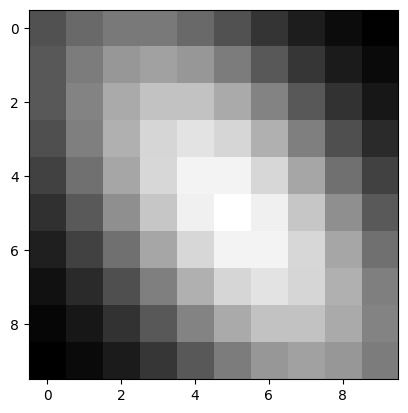

In [5]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

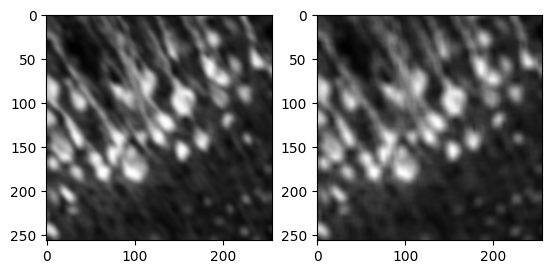

In [6]:
img_gpsf = conv(img, create_psf(psf_size), mode='same',
boundary='symm')

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(img_gpsf, 'grey')
plt.subplot(1, 2, 2)
plt.imshow(img_upsf, 'grey')

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [7]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    psf_flipped = np.flip(psf)
    
    for t in range (n_iterations):
        nenner = conv(img_deconv, psf, mode='same', boundary='symm')
        bruch = image / nenner
        klammer_ges = conv(bruch, psf_flipped, mode='same', boundary='symm')
        img_deconv = img_deconv * klammer_ges
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

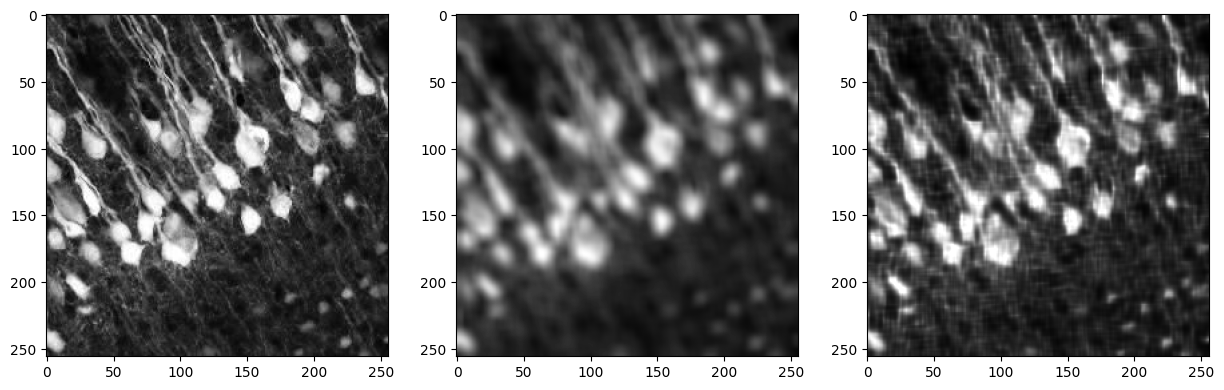

In [8]:
img_upsf_restored = richardson_lucy_deconvolution(img_upsf, psf, 100)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(img, 'gray')
plt.subplot(1, 3, 2); plt.imshow(img_upsf, 'gray')
plt.subplot(1, 3, 3); plt.imshow(img_upsf_restored, 'gray')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [10]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

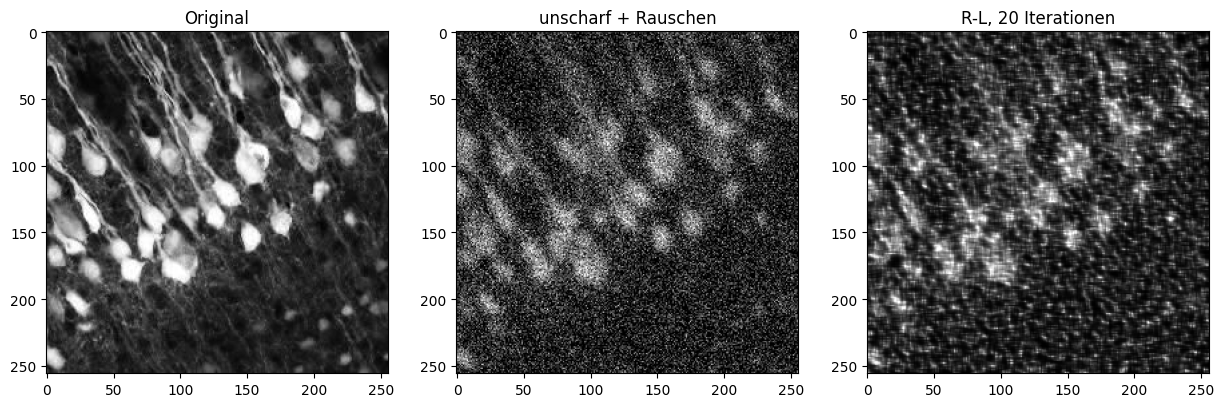

In [14]:
img_gpsf_noise = img_gpsf + noise
img_gpsf_noise = img_gpsf_noise.clip(0, 1)

img_gpsf_noise_restored = richardson_lucy_deconvolution(img_gpsf_noise, create_psf(psf_size), 20)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(img, 'gray');                     plt.title('Original')
plt.subplot(1, 3, 2); plt.imshow(img_gpsf_noise, 'gray');          plt.title('unscharf + Rauschen')
plt.subplot(1, 3, 3); plt.imshow(img_gpsf_noise_restored, 'gray'); plt.title('R-L, 20 Iterationen')
plt.show()

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

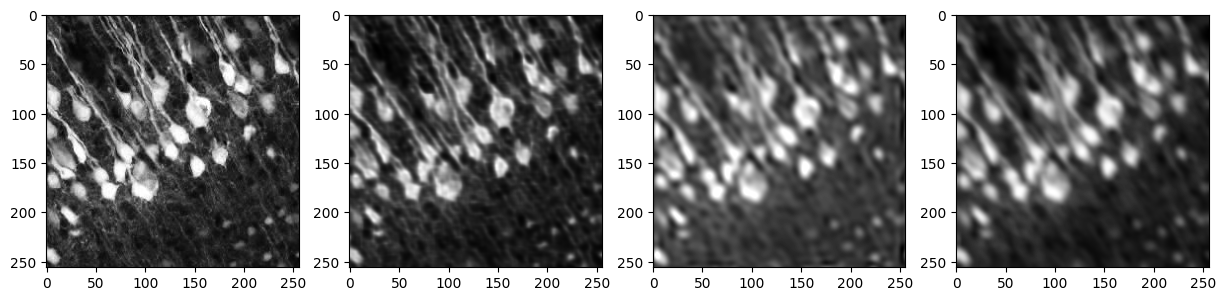

In [ ]:
img_gpsf_wiener_restored = wiener(img_gpsf, create_psf(psf_size), balance=0.3, clip=True)
img_gpsf_restored = richardson_lucy_deconvolution(img_gpsf, create_psf(psf_size), 100)

plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1); plt.imshow(img, 'gray')
plt.subplot(1, 4, 2); plt.imshow(img_gpsf_restored, 'gray')
plt.subplot(1, 4, 3); plt.imshow(img_gpsf_wiener_restored, 'gray')
plt.subplot(1, 4, 4); plt.imshow(img_gpsf, 'gray')
plt.show()

#komischerweise erhöht der Wiener Filter kaum die Schärfe...

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

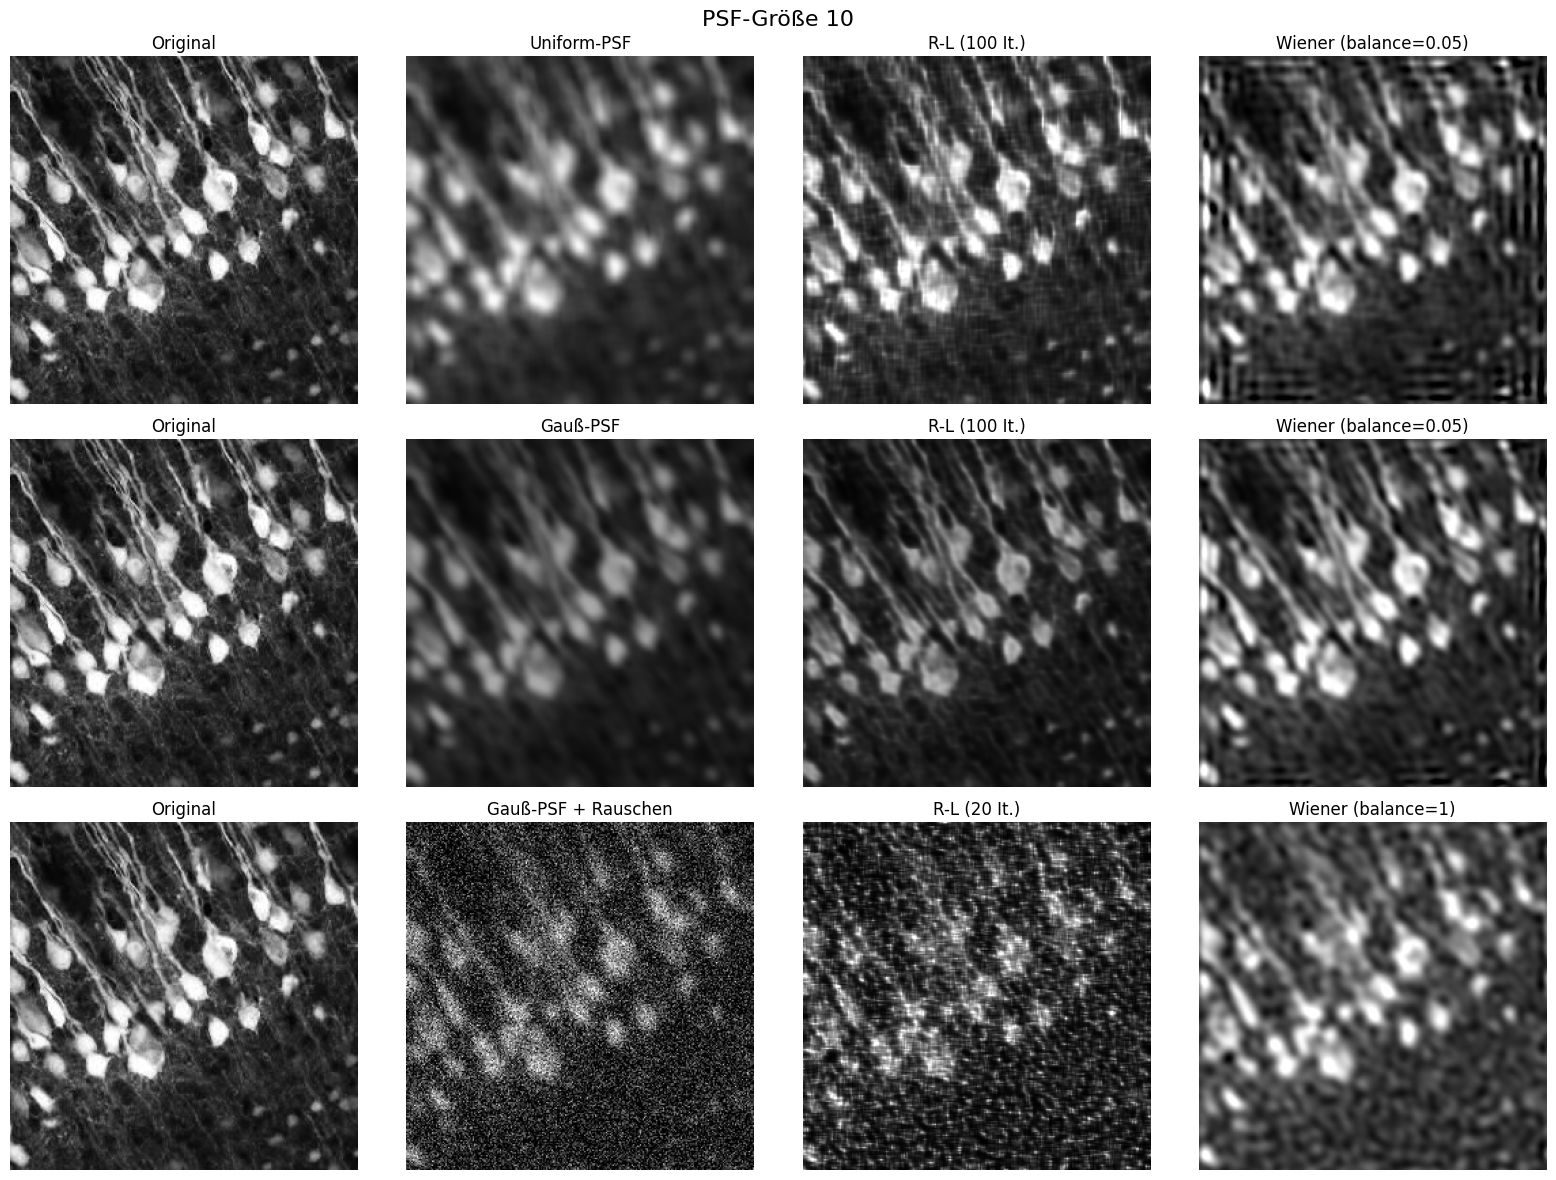

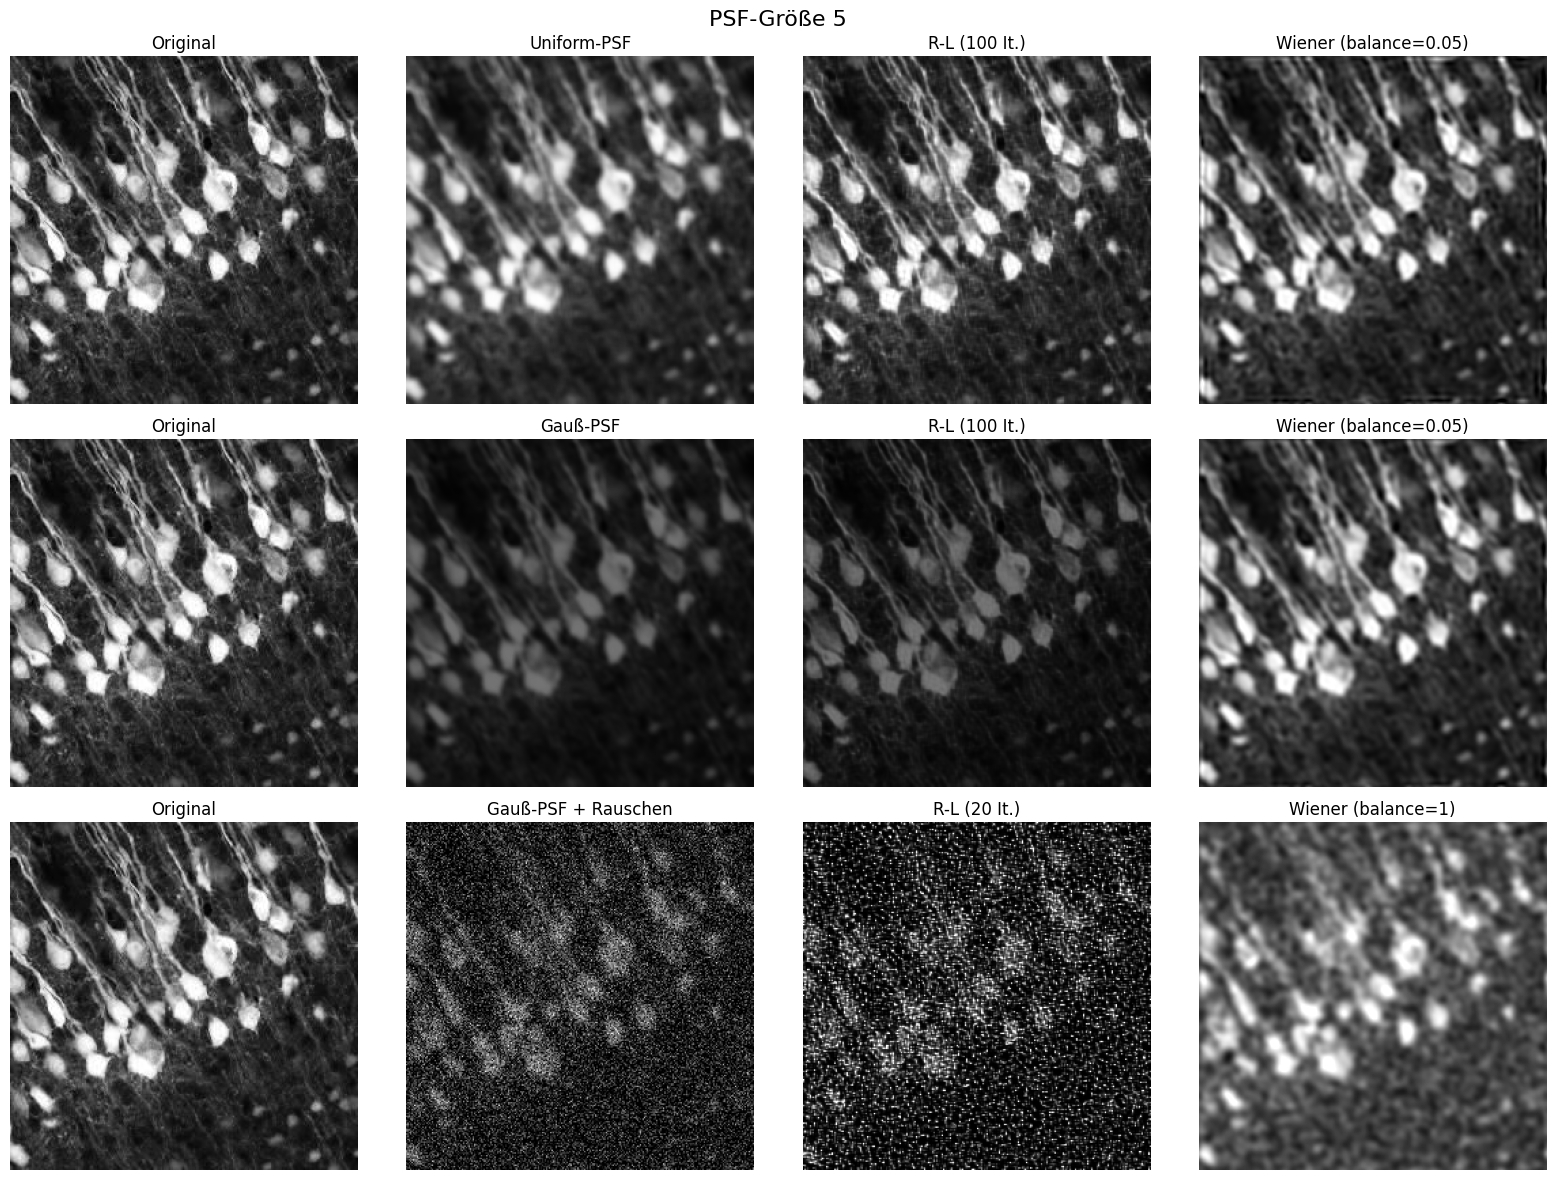

In [26]:
# Einstellungen zum Herumprobieren
psf_sizes = [10, 5]
n_iter_clean  = 100      # R-L-Iterationen ohne Rauschen
n_iter_noisy  = 20       # R-L-Iterationen mit Rauschen (weniger, sonst wird das Rauschen verstärkt)
balance_clean = 0.05     # Wiener-Bremse ohne Rauschen (klein = schärfer)
balance_noisy = 1        # Wiener-Bremse mit Rauschen (größer = Rauschen wird unterdrückt)

for size in psf_sizes:
    # 1. PSFs für diese Größe erzeugen
    uniform_psf = np.ones((size, size)) / size ** 2
    gauss_psf   = create_psf(size)

    # 2. Bild auf drei Arten verschmieren
    img_u  = conv(img, uniform_psf, mode='same', boundary='symm')
    img_g  = conv(img, gauss_psf,   mode='same', boundary='symm')
    img_gn = (img_g + noise).clip(0, 1)

    # 3. Liste der Fälle: (Name, verschmiertes Bild, passende PSF, Iterationen, balance)
    cases = [
        ('Uniform-PSF',         img_u,  uniform_psf, n_iter_clean, balance_clean),
        ('Gauß-PSF',            img_g,  gauss_psf,   n_iter_clean, balance_clean),
        ('Gauß-PSF + Rauschen', img_gn, gauss_psf,   n_iter_noisy, balance_noisy),
    ]

    # 4. Raster aus 3 Zeilen × 4 Spalten anlegen
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    fig.suptitle(f'PSF-Größe {size}', fontsize=16)

    for row, (name, blurred, p, n_iter, bal) in enumerate(cases):
        # 5. Beide Restaurierungen berechnen
        rl = richardson_lucy_deconvolution(blurred, p, n_iter)
        wi = wiener(blurred, p, balance=bal, clip=True)

        images = [img, blurred, rl, wi]
        titles = ['Original', name, f'R-L ({n_iter} It.)', f'Wiener (balance={bal})']

        # 6. Die vier Bilder dieser Zeile einzeichnen
        for col in range(4):
            axes[row, col].imshow(images[col], cmap='gray', vmin=0, vmax=1)
            axes[row, col].set_title(titles[col])
            axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()

**[Task 8.]()** Use a wrong PSF to restore the image

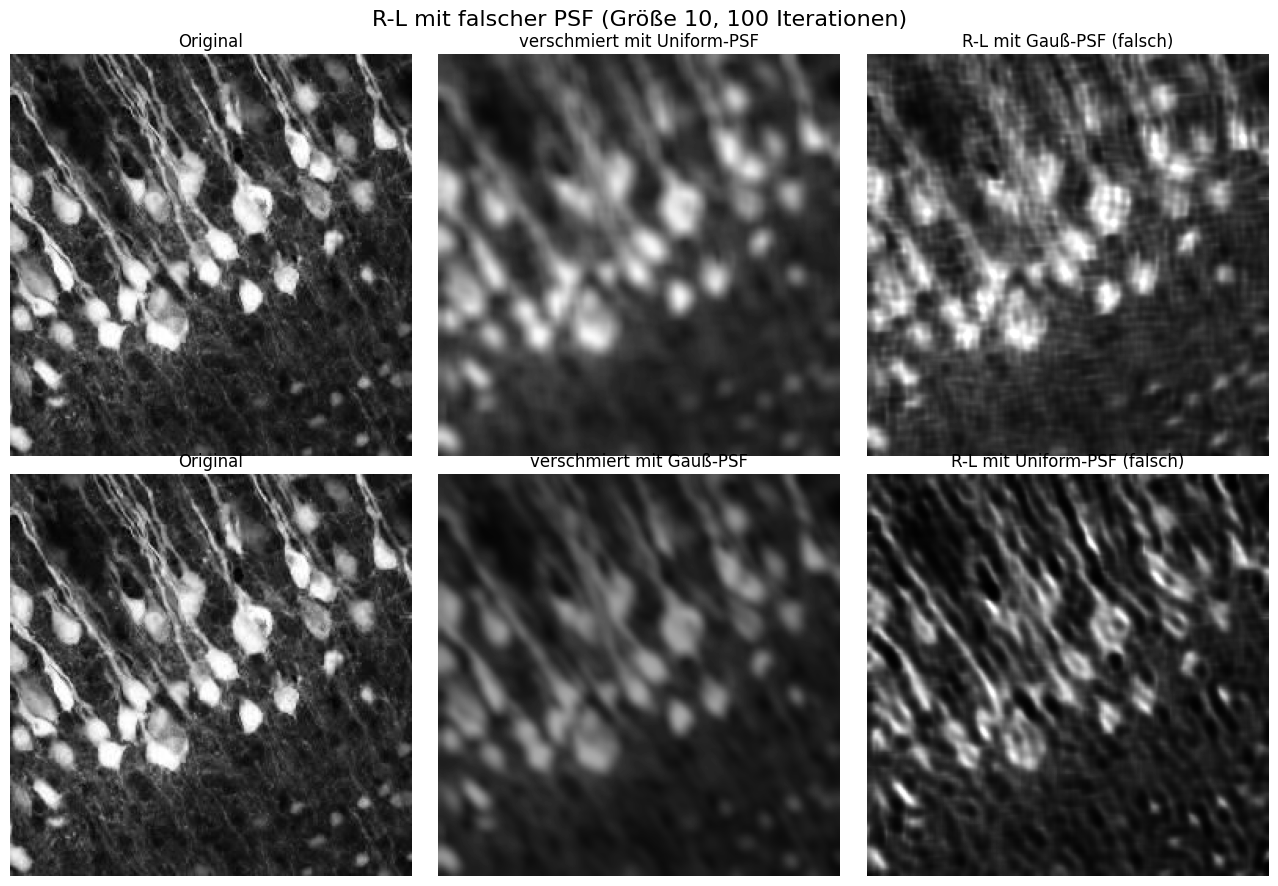

In [27]:
size = 10                # PSF-Größe; zum Vergleich auch mit 5 ausprobieren
n_iter = 100

uniform_psf = np.ones((size, size)) / size ** 2
gauss_psf   = create_psf(size)

img_u = conv(img, uniform_psf, mode='same', boundary='symm')
img_g = conv(img, gauss_psf,   mode='same', boundary='symm')

# (Name der echten PSF, verschmiertes Bild, FALSCHE PSF für R-L, Name der falschen PSF)
cases = [
    ('Uniform', img_u, gauss_psf,   'Gauß'),
    ('Gauß',    img_g, uniform_psf, 'Uniform'),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
fig.suptitle(f'R-L mit falscher PSF (Größe {size}, {n_iter} Iterationen)', fontsize=16)

for row, (true_name, blurred, wrong_psf, wrong_name) in enumerate(cases):
    restored = richardson_lucy_deconvolution(blurred, wrong_psf, n_iter)

    images = [img, blurred, restored]
    titles = ['Original',
              f'verschmiert mit {true_name}-PSF',
              f'R-L mit {wrong_name}-PSF (falsch)']

    for col in range(3):
        axes[row, col].imshow(images[col], cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_title(titles[col])
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()